# Alignment vs. Accuracy Difference — Demonstration with Synthetic Data

This notebook illustrates the **four scenarios** that arise when crossing the **geometric alignment** between two classifiers with the **absolute accuracy difference** measured on a test set:

| | Low accuracy difference (< 0.1) | High accuracy difference (> 0.1) |
|---|---|---|
| **Low alignment (< 0.5)** | Case 1 — different models, but accuracy doesn't capture it | Case 3 — different models, accuracy captures it |
| **High alignment (> 0.5)** | Case 4 — similar models, accuracy captures it | Case 2 — similar models, but accuracy doesn't capture it |

For each case we generate a 2D synthetic dataset, train two classifiers and compute:
- **Geometric alignment**: prediction agreement on a dense grid covering the full feature space.
- **Accuracy difference**: $|\text{acc}_A - \text{acc}_B|$ on the test set.

## 1. Import Required Libraries

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_classification, make_moons, make_blobs, make_circles
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier

# Ensure pyRA is on the path
ROOT = Path(".").resolve().parent
sys.path.insert(0, str(ROOT))
from pyRA.metrics import RashomonAlignment

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Helper Functions

- **`geometric_alignment_grid`**: generates a dense grid in the 2D feature space, obtains predictions from both models and computes the proportion of agreement (geometric alignment).
- **`accuracy_difference`**: computes $|\text{acc}_A - \text{acc}_B|$ on the test set.
- **`plot_case`**: plots side by side the decision boundaries of both models along with the agreement/disagreement map and the test set location.

In [4]:
def geometric_alignment_grid(model_a, model_b, xlim, ylim, resolution=200):
    """Compute geometric alignment on a dense grid."""
    xx, yy = np.meshgrid(
        np.linspace(xlim[0], xlim[1], resolution),
        np.linspace(ylim[0], ylim[1], resolution),
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    pred_a = model_a.predict(grid)
    pred_b = model_b.predict(grid)
    alignment = np.mean(pred_a == pred_b)
    return alignment, xx, yy, pred_a.reshape(xx.shape), pred_b.reshape(xx.shape)


def accuracy_difference(model_a, model_b, X_test, y_test):
    """Return (acc_a, acc_b, |acc_a - acc_b|)."""
    acc_a = accuracy_score(y_test, model_a.predict(X_test))
    acc_b = accuracy_score(y_test, model_b.predict(X_test))
    return acc_a, acc_b, abs(acc_a - acc_b)


def plot_case(title, model_a, model_b, name_a, name_b,
              X_train, y_train, X_test, y_test,
              xlim, ylim, alignment, acc_a, acc_b, acc_diff,
              resolution=200, view_xlim=None, view_ylim=None):
    """Plot decision boundaries, agreement map, and test set.

    The alignment is computed on the full (xlim, ylim) grid, while the figure
    can optionally display a zoomed region with (view_xlim, view_ylim).
    """
    xx, yy = np.meshgrid(
        np.linspace(xlim[0], xlim[1], resolution),
        np.linspace(ylim[0], ylim[1], resolution),
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    pred_a = model_a.predict(grid).reshape(xx.shape)
    pred_b = model_b.predict(grid).reshape(xx.shape)
    agree = (pred_a == pred_b).astype(int)
    test_agreement = model_a.predict(X_test) == model_b.predict(X_test)

    if view_xlim is None:
        view_xlim = xlim
    if view_ylim is None:
        view_ylim = ylim

    # class 0 -> light blue, class 1 -> light red
    cmap_light = ListedColormap(["#AAAAFF", "#FFAAAA"])
    cmap_agree = ListedColormap(["#d45d5d", "#9fb4c7"])

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    #fig.suptitle(title, fontsize=13, fontweight="bold", y=1.02)

    # --- Model A ---
    axes[0].contourf(xx, yy, pred_a, alpha=0.35, cmap=cmap_light, levels=[-0.5, 0.5, 1.5])
    axes[0].scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="bwr",
                    edgecolor="k", s=30, linewidth=0.5, zorder=3)
    axes[0].set_title(f"{name_a}  (acc={acc_a:.2f})")
    axes[0].set_xlim(view_xlim); axes[0].set_ylim(view_ylim)

    # --- Model B ---
    axes[1].contourf(xx, yy, pred_b, alpha=0.35, cmap=cmap_light, levels=[-0.5, 0.5, 1.5])
    axes[1].scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="bwr",
                    edgecolor="k", s=30, linewidth=0.5, zorder=3)
    axes[1].set_title(f"{name_b}  (acc={acc_b:.2f})")
    axes[1].set_xlim(view_xlim); axes[1].set_ylim(view_ylim)

    # --- Agreement map ---
    axes[2].contourf(xx, yy, agree, alpha=0.5, cmap=cmap_agree, levels=[-0.5, 0.5, 1.5])
    axes[2].scatter(X_test[test_agreement, 0], X_test[test_agreement, 1],
                    c="gold", edgecolor="k", s=30, linewidth=0.5, zorder=3,
                    label="test agreement")
    axes[2].scatter(X_test[~test_agreement, 0], X_test[~test_agreement, 1],
                    c="black", s=40, linewidth=0.8, zorder=4, marker="x",
                    label="test disagreement")
    axes[2].set_title(f"Agreement  (align={alignment:.2f}, Δacc={acc_diff:.2f})")
    axes[2].set_xlim(view_xlim); axes[2].set_ylim(view_ylim)
    agree_patch = mpatches.Patch(color="#9fb4c7", label="Agree")
    disagree_patch = mpatches.Patch(color="#d45d5d", label="Disagree")
    axes[2].legend(handles=[agree_patch, disagree_patch], loc="lower right", fontsize=8)

    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([])

    fig.tight_layout()
    fig.savefig(f"./img/{title.split(':')[0]}.pdf", dpi=300, bbox_inches="tight")
    plt.show()
    return fig

## 3. Base Classifiers

For each case we choose classifier pairs that, combined with the dataset shape and test set location, produce the desired behavior:

| Case | Model A | Model B | Strategy |
|------|---------|---------|----------|
| 1 — Low align / Low Δacc | SVM RBF γ=10 | MLP | Moons: both classify well, but extrapolate very differently on the wide grid [-15,15]² |
| 2 — High align / High Δacc | Logistic Regression | Decision Tree (depth=10) | Overlapping Gaussians: similar macro-boundary, DTree overfits in the data region |
| 3 — Low align / High Δacc | SVM linear | MLP | Concentric circles: linear SVM fails, MLP solves easily |
| 4 — High align / Low Δacc | SVM linear (C=1) | SVM linear (C=100) | Linearly separable classes: nearly identical boundaries |

## 4. Case 1 — Low Alignment & Low Accuracy Difference

> *"The models are different, but accuracy estimates don't capture it."*

**Idea**: We generate 2D data with `make_moons` and train an SVM RBF (γ=10) and an MLP. Both learn the moons well (**low accuracy difference** on the test set), but their decision boundaries in the full space are very different — the SVM creates tight islands around the data while the MLP extrapolates completely differently. Using a **very wide grid** ([-15, 15]²), the disagreement in extrapolation regions dominates, resulting in **low geometric alignment**.

This simulates the scenario where the real test set is located in a subspace where performance is similar, but across the full space the algorithms behave very differently.

Geometric alignment:             0.451
Accuracy model A (SVM RBF γ=10): 0.939
Accuracy model B (MLP):          0.939
Accuracy difference:             0.000


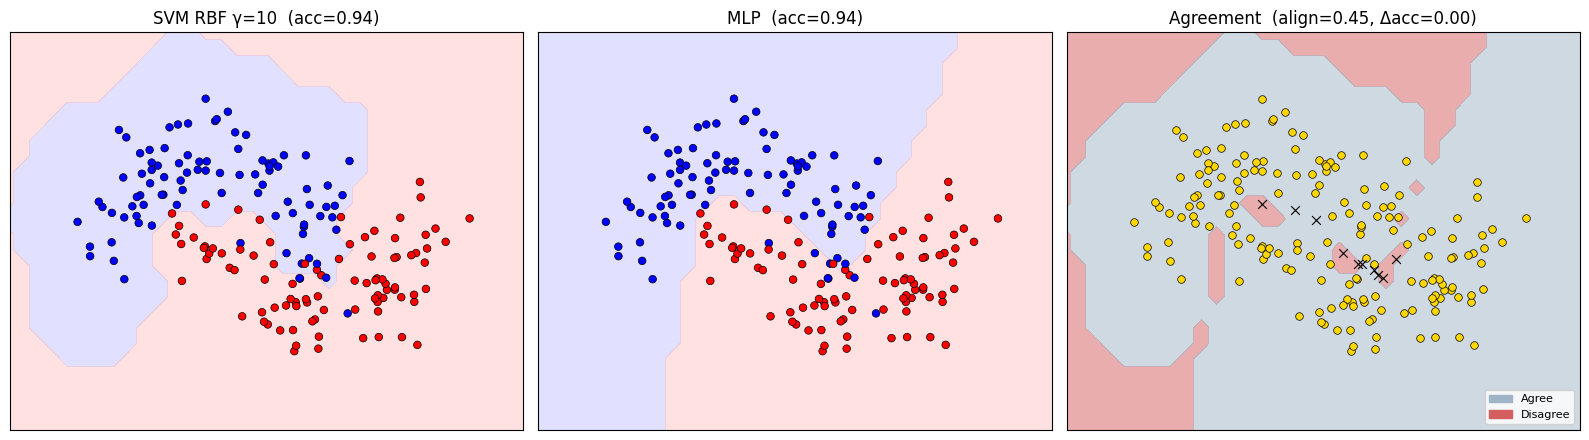

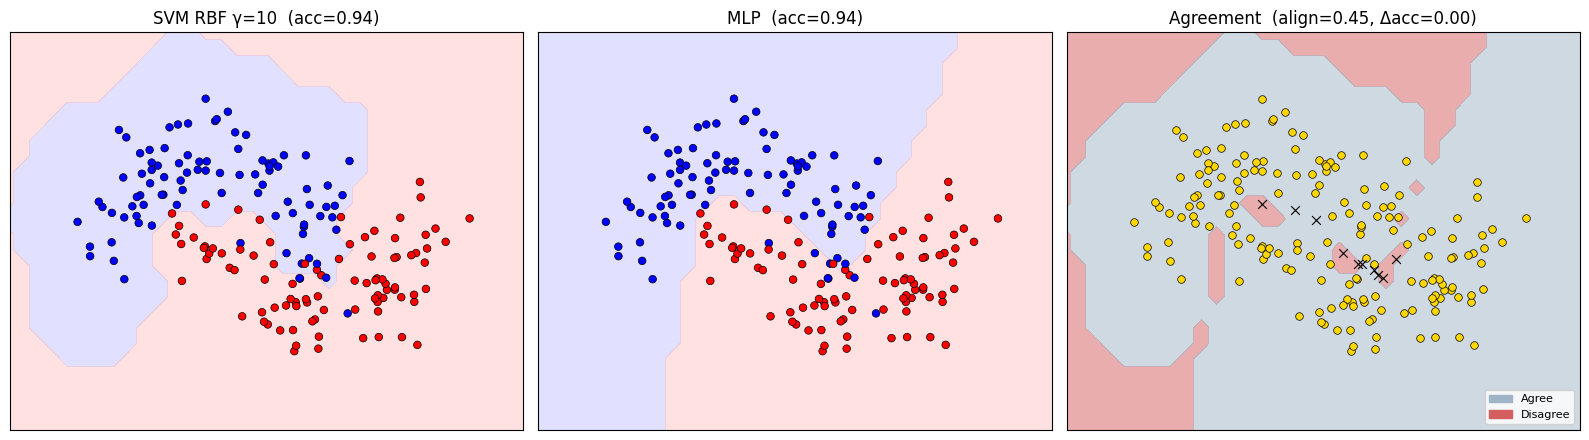

In [5]:
# --- Case 1: Low alignment & Low Δacc ---
# Moons: both models classify well, but extrapolate very differently
X_moons1, y_moons1 = make_moons(n_samples=600, noise=0.25, random_state=RANDOM_STATE)
X_train_1, X_test_1, y_train_1, y_test_1 = train_test_split(
    X_moons1, y_moons1, test_size=0.3, random_state=RANDOM_STATE, stratify=y_moons1
)

# SVM RBF (high gamma): creates tight islands around the data
model_a1 = SVC(kernel="rbf", gamma=10, C=100, random_state=RANDOM_STATE).fit(X_train_1, y_train_1)
# MLP: learns a smooth boundary that extrapolates very differently
model_b1 = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=2000,
                          random_state=RANDOM_STATE).fit(X_train_1, y_train_1)

# WIDE grid: most of it is extrapolation where models diverge drastically
xlim1 = (-15, 15)
ylim1 = (-15, 15)

align1, *_ = geometric_alignment_grid(model_a1, model_b1, xlim1, ylim1)
acc_a1, acc_b1, diff1 = accuracy_difference(model_a1, model_b1, X_test_1, y_test_1)

print(f"Geometric alignment:             {align1:.3f}")
print(f"Accuracy model A (SVM RBF γ=10): {acc_a1:.3f}")
print(f"Accuracy model B (MLP):          {acc_b1:.3f}")
print(f"Accuracy difference:             {diff1:.3f}")

# Zoom only the displayed figure around the data region.
view_xlim1 = (X_moons1[:, 0].min() - 0.5, X_moons1[:, 0].max() + 0.5)
view_ylim1 = (X_moons1[:, 1].min() - 0.5, X_moons1[:, 1].max() + 0.5)

plot_case("Case 1: Low Alignment & Low Accuracy Difference",
          model_a1, model_b1, "SVM RBF γ=10", "MLP",
          X_train_1, y_train_1, X_test_1, y_test_1,
          xlim1, ylim1, align1, acc_a1, acc_b1, diff1,
          view_xlim=view_xlim1, view_ylim=view_ylim1)

## 5. Case 2 — High Alignment & High Accuracy Difference

> *"The models are similar, but accuracy estimates don't capture it."*

**Idea**: We generate two overlapping Gaussians and train a Logistic Regression and a Decision Tree (depth 10). On the wide grid ([-15, 15]²), both models have the same macro-structure ("left = class 0, right = class 1"), resulting in **high geometric alignment**. However, the Decision Tree overfits in the overlap regions, producing an **accuracy difference > 0.1** on the test set.

This scenario occurs when the misalignment (however small) concentrates precisely in the region of feature space where the test data is located.

Geometric alignment:            0.947
Accuracy model A (LogReg):       0.761
Accuracy model B (DTree):        0.644
Accuracy difference:             0.117


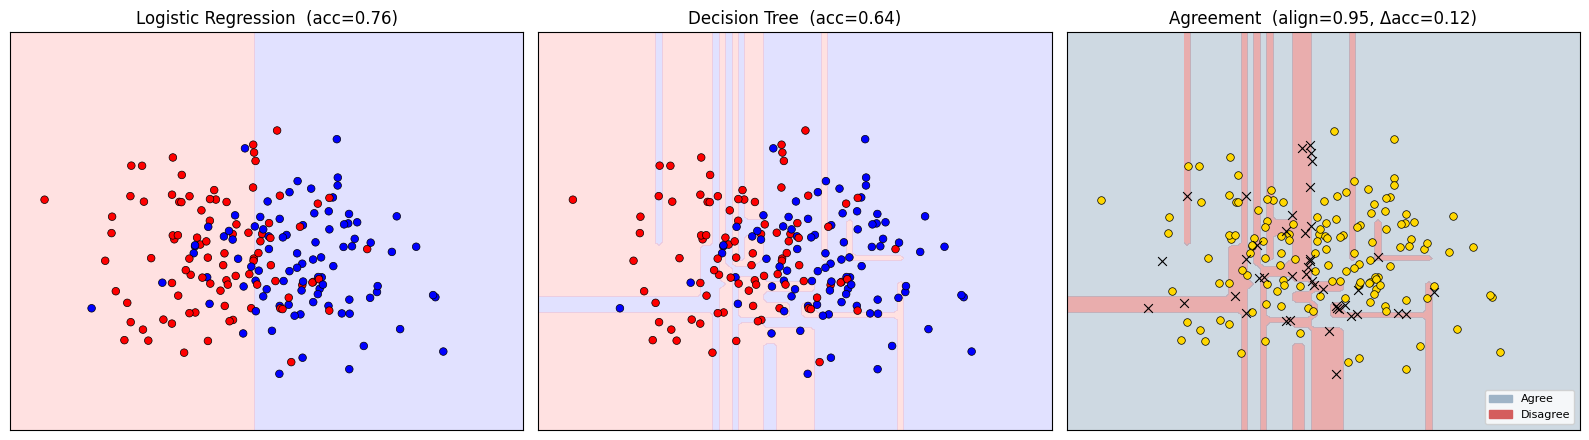

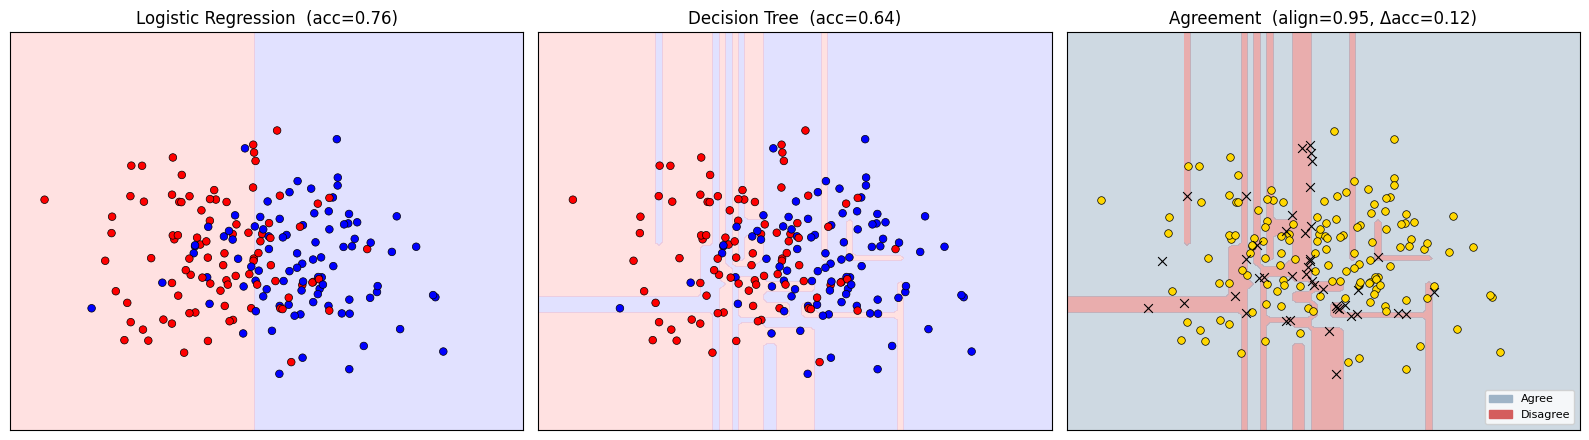

In [6]:
# --- Case 2: High alignment & High Δacc ---
# Overlapping Gaussians: models agree on the wide grid, but differ in accuracy
rng2 = np.random.RandomState(RANDOM_STATE)
X_ov = np.vstack([rng2.randn(300, 2) * 1.5 + [1, 0],
                   rng2.randn(300, 2) * 1.5 + [-1, 0]])
y_ov = np.array([0]*300 + [1]*300)

X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X_ov, y_ov, test_size=0.3, random_state=RANDOM_STATE, stratify=y_ov
)

# LogReg: generalizes better, smooth linear boundary
model_a2 = LogisticRegression(random_state=RANDOM_STATE).fit(X_train_2, y_train_2)
# Deep DTree: overfits at the boundary, but macro-structure similar to LogReg
model_b2 = DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE).fit(X_train_2, y_train_2)

xlim2 = (-15, 15)
ylim2 = (-15, 15)

align2, *_ = geometric_alignment_grid(model_a2, model_b2, xlim2, ylim2)
acc_a2, acc_b2, diff2 = accuracy_difference(model_a2, model_b2, X_test_2, y_test_2)

print(f"Geometric alignment:            {align2:.3f}")
print(f"Accuracy model A (LogReg):       {acc_a2:.3f}")
print(f"Accuracy model B (DTree):        {acc_b2:.3f}")
print(f"Accuracy difference:             {diff2:.3f}")

view_xlim2 = (X_ov[:, 0].min() - 0.75, X_ov[:, 0].max() + 0.75)
view_ylim2 = (X_ov[:, 1].min() - 0.75, X_ov[:, 1].max() + 0.75)

plot_case("Case 2: High Alignment & High Accuracy Difference",
          model_a2, model_b2, "Logistic Regression", "Decision Tree",
          X_train_2, y_train_2, X_test_2, y_test_2,
          xlim2, ylim2, align2, acc_a2, acc_b2, diff2,
          view_xlim=view_xlim2, view_ylim=view_ylim2)

## 6. Case 3 — Low Alignment & High Accuracy Difference (Expected Case)

> *"The models are different and accuracy estimates capture it."*

**Idea**: We use `make_circles` (concentric circles) and train a linear SVM against an MLP. The linear SVM cannot capture the circular boundary (**~65% acc**), while the MLP solves it easily (**~100% acc**). On the grid [-3, 3]², the boundaries are completely different (straight line vs. circle), resulting in **alignment < 0.5**.

The models diverge across the full space (**low alignment**) and the test set captures this difference (**high accuracy difference > 0.3**). This is the most intuitive and frequent case.

Geometric alignment:             0.469
Accuracy model A (SVM linear):    0.625
Accuracy model B (MLP):           1.000
Accuracy difference:              0.375


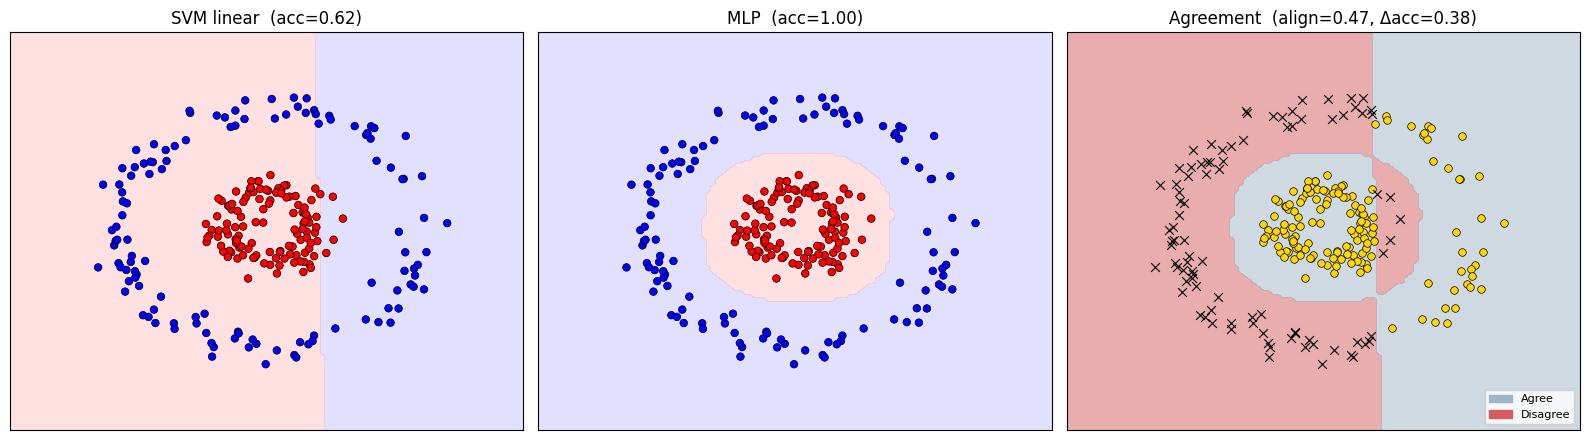

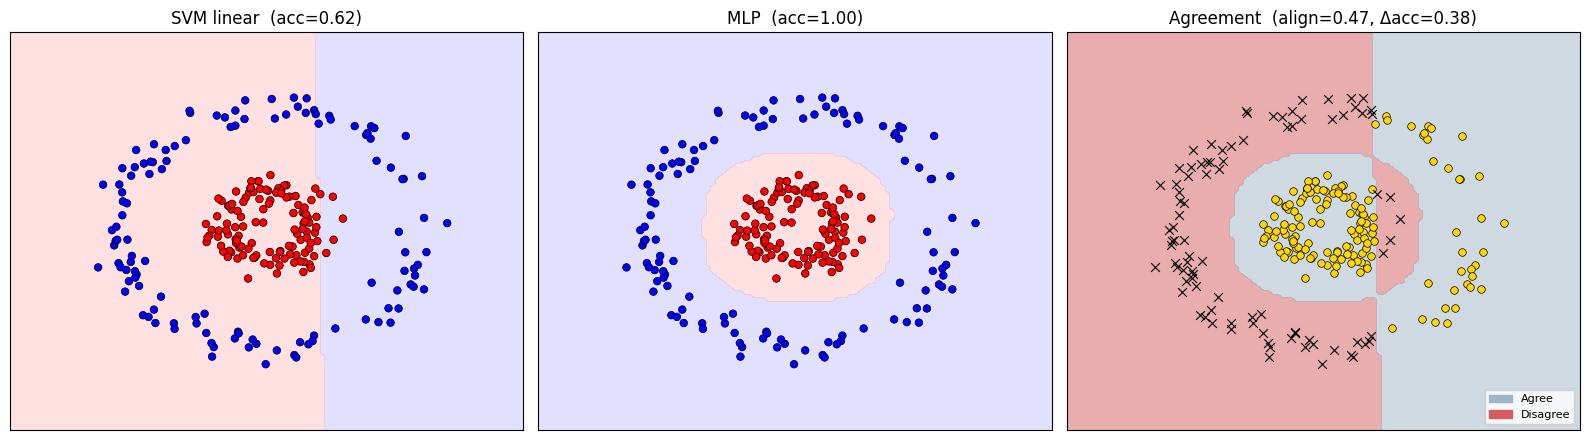

In [7]:
# --- Case 3: Low alignment & High Δacc ---
# Concentric circles: linear model fails, non-linear model solves it
X_circles, y_circles = make_circles(n_samples=800, noise=0.08, factor=0.3,
                                     random_state=RANDOM_STATE)
X_train_3, X_test_3, y_train_3, y_test_3 = train_test_split(
    X_circles, y_circles, test_size=0.3, random_state=RANDOM_STATE, stratify=y_circles
)

# SVM linear: cannot separate concentric circles
model_a3 = SVC(kernel="linear", C=1, random_state=RANDOM_STATE).fit(X_train_3, y_train_3)
# MLP: learns the circular boundary easily
model_b3 = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=2000,
                          random_state=RANDOM_STATE).fit(X_train_3, y_train_3)

xlim3 = (-3, 3)
ylim3 = (-3, 3)

align3, *_ = geometric_alignment_grid(model_a3, model_b3, xlim3, ylim3)
acc_a3, acc_b3, diff3 = accuracy_difference(model_a3, model_b3, X_test_3, y_test_3)

print(f"Geometric alignment:             {align3:.3f}")
print(f"Accuracy model A (SVM linear):    {acc_a3:.3f}")
print(f"Accuracy model B (MLP):           {acc_b3:.3f}")
print(f"Accuracy difference:              {diff3:.3f}")

view_xlim3 = (X_circles[:, 0].min() - 0.5, X_circles[:, 0].max() + 0.5)
view_ylim3 = (X_circles[:, 1].min() - 0.5, X_circles[:, 1].max() + 0.5)

plot_case("Case 3: Low Alignment & High Accuracy Difference",
          model_a3, model_b3, "SVM linear", "MLP",
          X_train_3, y_train_3, X_test_3, y_test_3,
          xlim3, ylim3, align3, acc_a3, acc_b3, diff3,
          view_xlim=view_xlim3, view_ylim=view_ylim3)

## 7. Case 4 — High Alignment & Low Accuracy Difference (Expected Case)

> *"The models are similar and accuracy estimates capture it."*

**Idea**: Linearly separable dataset (`make_classification` with well-separated classes). We train two linear SVMs with slightly different regularization (C=1 vs C=100). The boundaries are nearly identical (**high alignment ≈ 1.0**) and the test set accuracy is also very close (**low difference ≈ 0.0**).

This is the least "interesting" case since alignment and accuracy tell the same story: the models are equivalent.

Geometric alignment:             1.000
Accuracy model A (SVM C=1):       1.000
Accuracy model B (SVM C=100):     1.000
Accuracy difference:              0.000


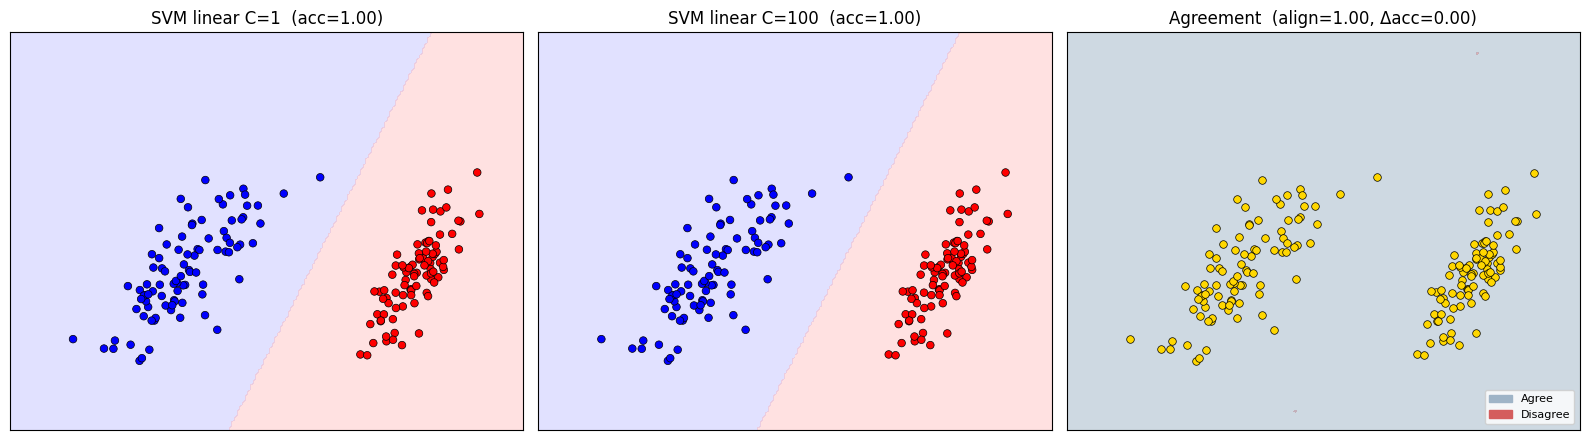

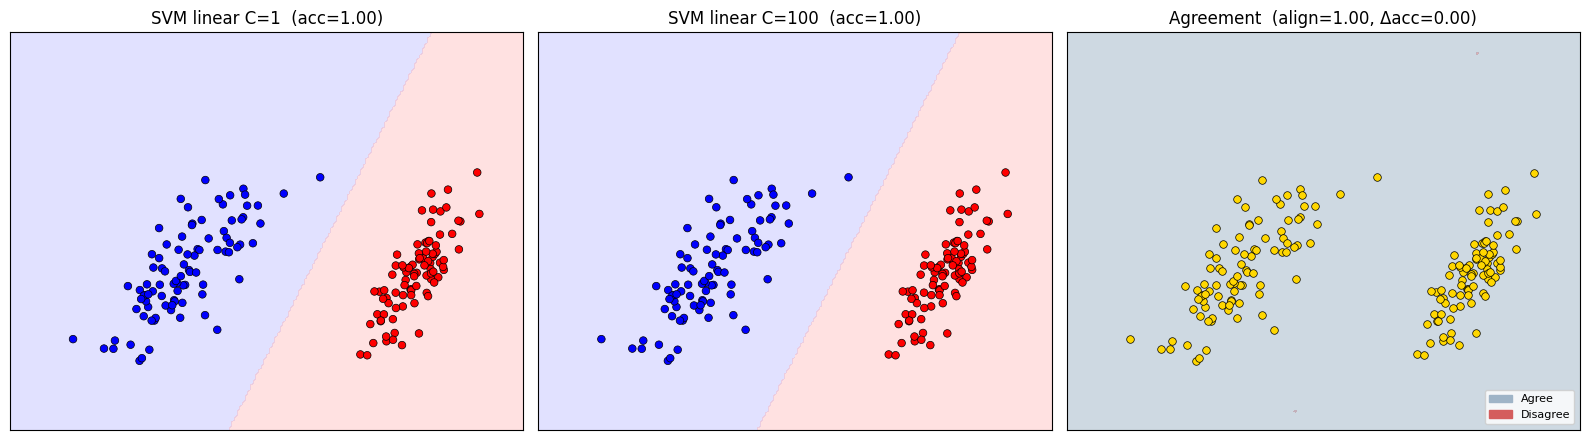

In [8]:
# --- Case 4: High alignment & Low Δacc ---
# Well-separated, linearly separable classes
X_lin, y_lin = make_classification(
    n_samples=600, n_features=2, n_informative=2, n_redundant=0,
    n_clusters_per_class=1, class_sep=3.0, random_state=RANDOM_STATE,
)
X_train_4, X_test_4, y_train_4, y_test_4 = train_test_split(
    X_lin, y_lin, test_size=0.3, random_state=RANDOM_STATE, stratify=y_lin
)

# Two nearly identical linear SVMs
model_a4 = SVC(kernel="linear", C=1, random_state=RANDOM_STATE).fit(X_train_4, y_train_4)
model_b4 = SVC(kernel="linear", C=100, random_state=RANDOM_STATE).fit(X_train_4, y_train_4)

xlim4 = (X_lin[:, 0].min() - 1, X_lin[:, 0].max() + 1)
ylim4 = (X_lin[:, 1].min() - 1, X_lin[:, 1].max() + 1)

align4, *_ = geometric_alignment_grid(model_a4, model_b4, xlim4, ylim4)
acc_a4, acc_b4, diff4 = accuracy_difference(model_a4, model_b4, X_test_4, y_test_4)

print(f"Geometric alignment:             {align4:.3f}")
print(f"Accuracy model A (SVM C=1):       {acc_a4:.3f}")
print(f"Accuracy model B (SVM C=100):     {acc_b4:.3f}")
print(f"Accuracy difference:              {diff4:.3f}")

view_xlim4 = (X_lin[:, 0].min() - 0.75, X_lin[:, 0].max() + 0.75)
view_ylim4 = (X_lin[:, 1].min() - 0.75, X_lin[:, 1].max() + 0.75)

plot_case("Case 4: High Alignment & Low Accuracy Difference",
          model_a4, model_b4, "SVM linear C=1", "SVM linear C=100",
          X_train_4, y_train_4, X_test_4, y_test_4,
          xlim4, ylim4, align4, acc_a4, acc_b4, diff4,
          view_xlim=view_xlim4, view_ylim=view_ylim4)

## 8. Comparative Visualization of All 4 Cases

Below we show a 4×2 figure with the agreement/disagreement map (left) and overlaid decision boundaries (right) for each case, annotated with alignment and accuracy difference values.

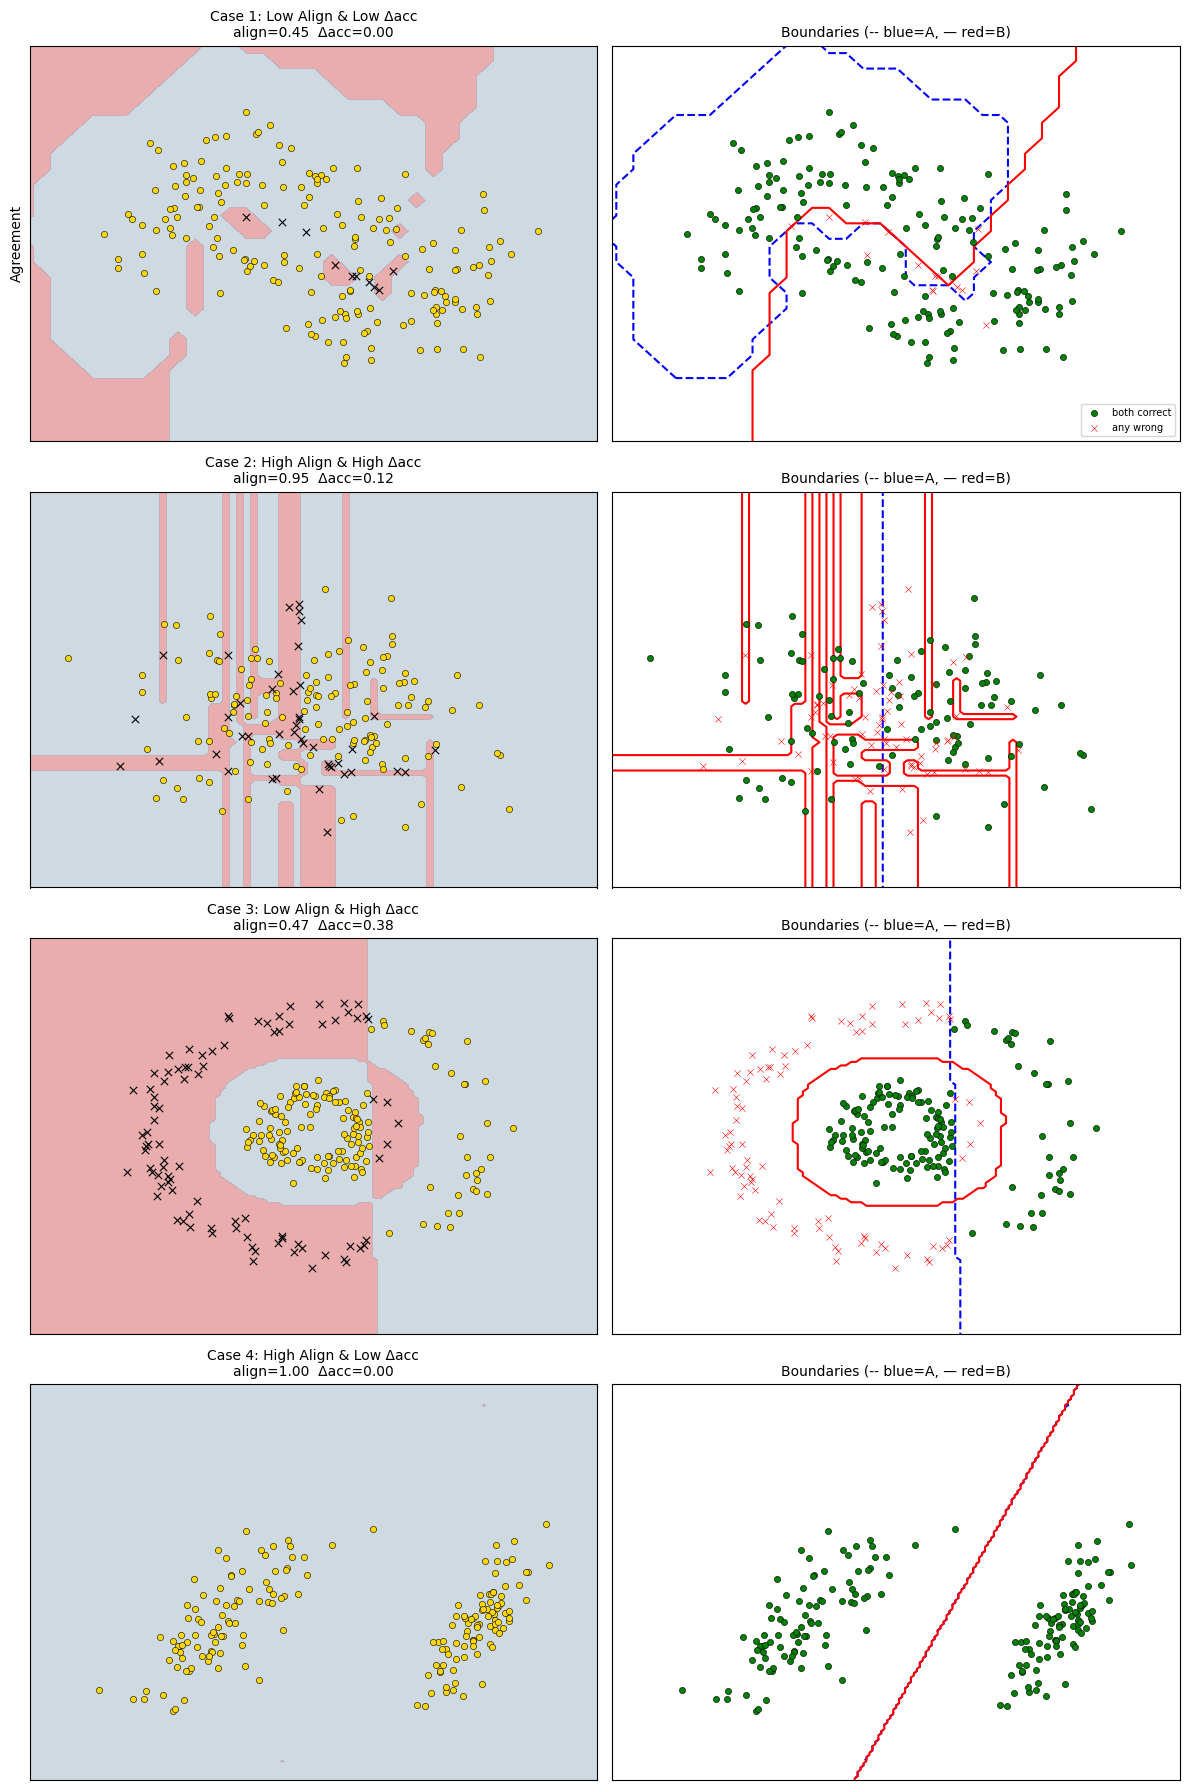

In [36]:
# --- Comparative 4x2 visualization ---
cases = [
    ("Case 1: Low Align & Low Δacc",  model_a1, model_b1, X_test_1, y_test_1, xlim1, ylim1, align1, diff1),
    ("Case 2: High Align & High Δacc", model_a2, model_b2, X_test_2, y_test_2, xlim2, ylim2, align2, diff2),
    ("Case 3: Low Align & High Δacc",  model_a3, model_b3, X_test_3, y_test_3, xlim3, ylim3, align3, diff3),
    ("Case 4: High Align & Low Δacc",  model_a4, model_b4, X_test_4, y_test_4, xlim4, ylim4, align4, diff4),
]

view_xlim1 = (X_moons1[:, 0].min() - 0.5, X_moons1[:, 0].max() + 0.5)
view_ylim1 = (X_moons1[:, 1].min() - 0.5, X_moons1[:, 1].max() + 0.5)
view_xlim2 = (X_ov[:, 0].min() - 0.75, X_ov[:, 0].max() + 0.75)
view_ylim2 = (X_ov[:, 1].min() - 0.75, X_ov[:, 1].max() + 0.75)
view_xlim3 = (X_circles[:, 0].min() - 0.5, X_circles[:, 0].max() + 0.5)
view_ylim3 = (X_circles[:, 1].min() - 0.5, X_circles[:, 1].max() + 0.5)
view_xlim4 = (X_lin[:, 0].min() - 0.75, X_lin[:, 0].max() + 0.75)
view_ylim4 = (X_lin[:, 1].min() - 0.75, X_lin[:, 1].max() + 0.75)

view_limits = [
    (view_xlim1, view_ylim1),
    (view_xlim2, view_ylim2),
    (view_xlim3, view_ylim3),
    (view_xlim4, view_ylim4),
]

cmap_agree = ListedColormap(["#d45d5d", "#9fb4c7"])

fig, axes = plt.subplots(4, 2, figsize=(12, 18))

for row, (title, ma, mb, Xt, yt, xl, yl, al, di) in enumerate(cases):
    res = 200
    xx, yy = np.meshgrid(np.linspace(xl[0], xl[1], res), np.linspace(yl[0], yl[1], res))
    grid = np.c_[xx.ravel(), yy.ravel()]
    pa = ma.predict(grid).reshape(xx.shape)
    pb = mb.predict(grid).reshape(xx.shape)
    agree = (pa == pb).astype(int)
    test_agreement = ma.predict(Xt) == mb.predict(Xt)

    display_xlim, display_ylim = view_limits[row]

    # Column 0: agreement map + test set
    ax0 = axes[row, 0]
    ax0.contourf(xx, yy, agree, alpha=0.5, cmap=cmap_agree, levels=[-0.5, 0.5, 1.5])
    ax0.scatter(Xt[test_agreement, 0], Xt[test_agreement, 1],
                c="gold", edgecolor="k", s=20, linewidth=0.4, zorder=3)
    ax0.scatter(Xt[~test_agreement, 0], Xt[~test_agreement, 1],
                c="black", s=28, linewidth=0.8, zorder=4, marker="x")
    ax0.set_title(f"{title}\nalign={al:.2f}  Δacc={di:.2f}", fontsize=10)
    ax0.set_xlim(display_xlim); ax0.set_ylim(display_ylim)
    ax0.set_xticks([]); ax0.set_yticks([])
    if row == 0:
        ax0.set_ylabel("Agreement", fontsize=10)

    # Column 1: overlaid boundaries + correct/wrong on test set
    ax1 = axes[row, 1]
    ax1.contour(xx, yy, pa, levels=[0.5], colors="blue", linewidths=1.5, linestyles="--")
    ax1.contour(xx, yy, pb, levels=[0.5], colors="red",  linewidths=1.5, linestyles="-")
    correct_a = (ma.predict(Xt) == yt)
    correct_b = (mb.predict(Xt) == yt)
    both_correct = correct_a & correct_b
    any_wrong = ~both_correct
    ax1.scatter(Xt[both_correct, 0], Xt[both_correct, 1], c="green",
                edgecolor="k", s=20, linewidth=0.4, zorder=3, label="both correct")
    ax1.scatter(Xt[any_wrong, 0], Xt[any_wrong, 1], c="red",
                s=20, linewidth=0.4, zorder=3, marker="x", label="any wrong")
    ax1.set_xlim(display_xlim); ax1.set_ylim(display_ylim)
    ax1.set_xticks([]); ax1.set_yticks([])
    ax1.set_title("Boundaries (-- blue=A, — red=B)", fontsize=10)
    if row == 0:
        ax1.legend(fontsize=7, loc="lower right")

fig.tight_layout()
plt.show()

## 9. Summary Plot — Alignment vs. Accuracy Difference

Scatter plot positioning each case in the (geometric alignment × accuracy difference) plane, with reference lines dividing the four quadrants.

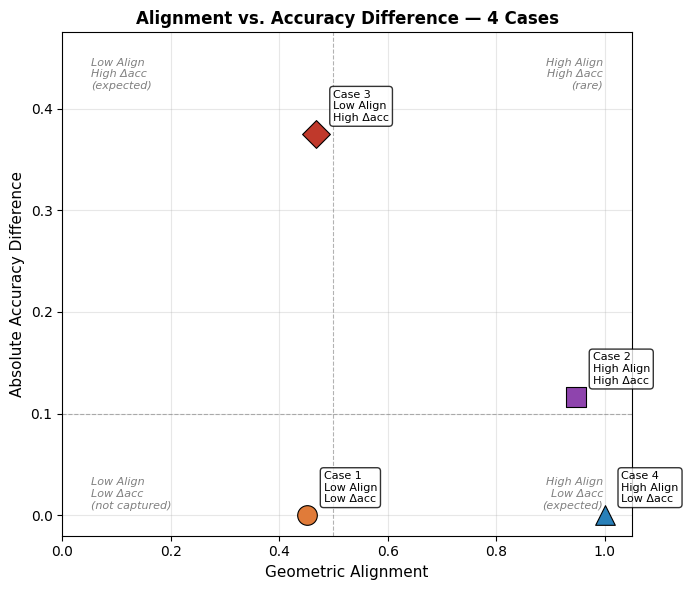

In [28]:
# --- Scatter Alignment vs Δacc ---
fig, ax = plt.subplots(figsize=(7, 6))

labels = ["Case 1\nLow Align\nLow Δacc",
          "Case 2\nHigh Align\nHigh Δacc",
          "Case 3\nLow Align\nHigh Δacc",
          "Case 4\nHigh Align\nLow Δacc"]
aligns = [align1, align2, align3, align4]
diffs  = [diff1,  diff2,  diff3,  diff4]
colors = ["#e07b39", "#8e44ad", "#c0392b", "#2980b9"]
markers = ["o", "s", "D", "^"]

for lbl, a, d, c, m in zip(labels, aligns, diffs, colors, markers):
    ax.scatter(a, d, s=200, c=c, marker=m, edgecolor="k", linewidth=0.8, zorder=5)
    ax.annotate(lbl, (a, d), textcoords="offset points", xytext=(12, 8),
                fontsize=8, ha="left", va="bottom",
                bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.8))

# Reference lines at fixed thresholds (align=0.5, Δacc=0.1)
ax.axvline(0.5, color="gray", linestyle="--", linewidth=0.8, alpha=0.6)
ax.axhline(0.1, color="gray", linestyle="--", linewidth=0.8, alpha=0.6)

# Quadrant labels
ax.text(0.05, 0.95, "Low Align\nHigh Δacc\n(expected)", transform=ax.transAxes,
        fontsize=8, va="top", ha="left", color="gray", style="italic")
ax.text(0.95, 0.95, "High Align\nHigh Δacc\n(rare)", transform=ax.transAxes,
        fontsize=8, va="top", ha="right", color="gray", style="italic")
ax.text(0.05, 0.05, "Low Align\nLow Δacc\n(not captured)", transform=ax.transAxes,
        fontsize=8, va="bottom", ha="left", color="gray", style="italic")
ax.text(0.95, 0.05, "High Align\nLow Δacc\n(expected)", transform=ax.transAxes,
        fontsize=8, va="bottom", ha="right", color="gray", style="italic")

ax.set_xlabel("Geometric Alignment", fontsize=11)
ax.set_ylabel("Absolute Accuracy Difference", fontsize=11)
ax.set_title("Alignment vs. Accuracy Difference — 4 Cases", fontsize=12, fontweight="bold")
ax.set_xlim(0, 1.05)
ax.set_ylim(-0.02, max(diffs) + 0.1)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()